# Notebook 9 - Few-Shot Evaluation (1 / 3 / 5-shot)

**Question:** when a *new person* (never seen in training) is enrolled with only k iris images, how well can each model
verify and identify them?

Protocol (test identities are disjoint from training, verified in Notebook 3):
1. For each episode, draw `k` support images per identity (enrolment). The remaining images are queries.
2. Enrolment template = mean of the k L2-normalised embeddings (re-normalised). Score = cosine similarity.
3. **Verification:** every query vs every template. Own template = genuine, others = impostor -> AUC, EER, TAR@FAR.
4. **Identification:** every query vs all templates -> Rank-1 / Rank-5.
5. Repeat for many random episodes. **All models see exactly the same episodes**, so differences are paired.

Needs only the `*_embeddings.npz` files saved by Notebooks 6 and 8 (no GPU, no torch).

In [1]:
# CELL 1: Imports
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.4 | pandas 3.1.0


In [2]:
# CELL 2: Configuration
SUFFIX = ""            # use "_v2" after you re-run the v2 pipeline
SEED = 42
SPLIT = "test"
SHOTS = [1, 3, 5]
N_EPISODES = 200       # random support draws per shot
TAR_FARS = [0.01, 0.001]

BASE = Path("..")
OUTPUT_DIR = BASE / f"few_shot_evaluation{SUFFIX}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# name -> (folder, file name, candidate array keys). Missing entries are skipped automatically.
H = BASE / f"hybrid_quantum_metric_learning{SUFFIX}"
MODELS = {
    "NB5 Siamese 128-D":            (BASE / f"siamese_metric_learning{SUFFIX}", f"{SPLIT}_embeddings.npz", ["embeddings", "embeddings_128"]),
    "NB6 classical 8-D":            (BASE / f"classical_projection_baseline{SUFFIX}", f"{SPLIT}_embeddings.npz", ["embeddings_8"]),
    "NB8 classical_linear 8-D":     (H, f"classical_linear_{SPLIT}_embeddings.npz", ["embeddings_final"]),
    "NB8 hybrid_quantum 8-D":       (H, f"hybrid_quantum_{SPLIT}_embeddings.npz", ["embeddings_final"]),
    "NB8 quantum_product 8-D":      (H, f"hybrid_quantum_product_{SPLIT}_embeddings.npz", ["embeddings_final"]),
}
print("Output:", OUTPUT_DIR, "| shots:", SHOTS, "| episodes:", N_EPISODES)

Output: ..\few_shot_evaluation | shots: [1, 3, 5] | episodes: 200


In [3]:
# CELL 3: Load embeddings and sanity-check them
def l2norm(x):
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-12, None)

EMB, ID = {}, None
for name, (folder, fname, keys) in MODELS.items():
    path = folder / fname
    if not path.exists():
        print(f"SKIP  {name:28s} (not found: {path})"); continue
    z = np.load(path, allow_pickle=True)
    key = next((k for k in keys if k in z.files), None)
    if key is None:
        print(f"SKIP  {name:28s} (no key among {keys}; has {z.files})"); continue
    emb, ids = l2norm(z[key].astype(np.float64)), np.asarray(z["identities"])
    if ID is None:
        ID = ids
    elif not np.array_equal(ID, ids):
        print(f"SKIP  {name:28s} (image order differs from the first model)"); continue
    EMB[name] = emb
    print(f"OK    {name:28s} {emb.shape}")

assert EMB, "No embeddings found - check the folders in CELL 2."
classes, inv = np.unique(ID, return_inverse=True)
counts = np.bincount(inv)
print(f"\nIdentities: {len(classes)} | images per identity: min {counts.min()}, max {counts.max()}")
assert counts.min() > max(SHOTS), "Need at least max(SHOTS)+1 images per identity."
IDX_BY_CLASS = [np.where(inv == c)[0] for c in range(len(classes))]

SKIP  NB5 Siamese 128-D            (not found: ..\siamese_metric_learning\test_embeddings.npz)
OK    NB6 classical 8-D            (3000, 8)
OK    NB8 classical_linear 8-D     (3000, 8)
OK    NB8 hybrid_quantum 8-D       (3000, 8)
OK    NB8 quantum_product 8-D      (3000, 8)

Identities: 300 | images per identity: min 10, max 10


In [4]:
# CELL 4: Episode sampling and metrics
def make_episode(rng, k):
    support, query, qlab = [], [], []
    for c, idx in enumerate(IDX_BY_CLASS):
        perm = rng.permutation(idx)
        support.append(perm[:k]); query.extend(perm[k:]); qlab.extend([c] * (len(perm) - k))
    return support, np.array(query), np.array(qlab)

def evaluate(emb, support, query, qlab):
    protos = l2norm(np.stack([emb[s].mean(axis=0) for s in support]))
    sims = emb[query] @ protos.T                       # (Q, C) cosine scores
    rows = np.arange(len(query))
    gen = sims[rows, qlab]
    mask = np.ones_like(sims, bool); mask[rows, qlab] = False
    imp = sims[mask]
    # identification: rank of the true template
    rank = (sims > gen[:, None]).sum(axis=1) + 1
    # verification
    imp_sorted = np.sort(imp)
    below = np.searchsorted(imp_sorted, gen, side="left")
    equal = np.searchsorted(imp_sorted, gen, side="right") - below
    auc = float(np.mean((below + 0.5 * equal) / len(imp_sorted)))
    thr = np.unique(np.quantile(np.concatenate([gen, imp]), np.linspace(0, 1, 2001)))
    far = 1.0 - np.searchsorted(imp_sorted, thr, side="left") / len(imp_sorted)
    frr = np.searchsorted(np.sort(gen), thr, side="left") / len(gen)
    i = int(np.argmin(np.abs(far - frr)))
    out = {"rank1": float((rank <= 1).mean()), "rank5": float((rank <= 5).mean()),
           "auc": auc, "eer": float((far[i] + frr[i]) / 2)}
    for f in TAR_FARS:
        ok = far <= f
        out[f"tar@far{f:g}"] = float(1.0 - frr[ok].min()) if ok.any() else 0.0
    return out

# quick self-check: identical embeddings for the same class must give perfect scores
_toy = np.eye(4)[inv % 4] if len(classes) >= 4 else None
print("Evaluation functions ready.")

Evaluation functions ready.


In [5]:
# CELL 5: Run all episodes (same episodes for every model)
rng = np.random.default_rng(SEED)
records = []
for k in SHOTS:
    for ep in range(N_EPISODES):
        support, query, qlab = make_episode(rng, k)
        for name, emb in EMB.items():
            r = evaluate(emb, support, query, qlab)
            r.update(model=name, shots=k, episode=ep)
            records.append(r)
    print(f"{k}-shot done ({N_EPISODES} episodes x {len(EMB)} models)")
episodes_df = pd.DataFrame(records)
episodes_df.to_csv(OUTPUT_DIR / "episode_results.csv", index=False)

1-shot done (200 episodes x 4 models)
3-shot done (200 episodes x 4 models)
5-shot done (200 episodes x 4 models)


In [6]:
# CELL 6: Summary table (mean +- std over episodes, 95% percentile interval)
metrics = ["rank1", "rank5", "auc", "eer"] + [f"tar@far{f:g}" for f in TAR_FARS]
rows = []
for (model, k), g in episodes_df.groupby(["model", "shots"], sort=False):
    row = {"model": model, "shots": k}
    for m in metrics:
        v = g[m].values
        row[m] = v.mean(); row[m + "_std"] = v.std(ddof=1)
        row[m + "_lo"], row[m + "_hi"] = np.percentile(v, [2.5, 97.5])
    rows.append(row)
summary_df = pd.DataFrame(rows)
summary_df.to_csv(OUTPUT_DIR / "few_shot_summary.csv", index=False)

for k in SHOTS:
    s = summary_df[summary_df.shots == k]
    print(f"\n===== {k}-shot =====")
    print(pd.DataFrame({
        "model": s.model,
        "Rank-1 %": (100 * s.rank1).round(2),
        "Rank-5 %": (100 * s.rank5).round(2),
        "AUC": s.auc.round(4),
        "EER %": (100 * s.eer).round(2),
        "EER std": (100 * s.eer_std).round(2),
        f"TAR@FAR1% %": (100 * s["tar@far0.01"]).round(2),
    }).to_string(index=False))


===== 1-shot =====
                   model  Rank-1 %  Rank-5 %    AUC  EER %  EER std  TAR@FAR1% %
       NB6 classical 8-D     14.57     29.10 0.8733  22.01     0.38        21.98
NB8 classical_linear 8-D     14.20     28.65 0.8733  21.94     0.37        21.81
  NB8 hybrid_quantum 8-D     13.37     28.54 0.8792  21.34     0.42        22.21
 NB8 quantum_product 8-D     13.80     28.72 0.8780  21.24     0.41        22.27

===== 3-shot =====
                   model  Rank-1 %  Rank-5 %    AUC  EER %  EER std  TAR@FAR1% %
       NB6 classical 8-D     13.20     30.96 0.9013  18.50     0.28        19.70
NB8 classical_linear 8-D     12.61     30.24 0.9020  18.33     0.28        19.35
  NB8 hybrid_quantum 8-D     12.59     31.42 0.9069  17.80     0.31        20.94
 NB8 quantum_product 8-D     13.10     31.33 0.9057  17.85     0.30        20.98

===== 5-shot =====
                   model  Rank-1 %  Rank-5 %    AUC  EER %  EER std  TAR@FAR1% %
       NB6 classical 8-D     13.57     32.46 0.90

In [7]:
# CELL 7: Paired comparison across episodes (same support/query draws for every model)
def paired(a, b, k, metric="eer"):
    x = episodes_df[(episodes_df.model == a) & (episodes_df.shots == k)].sort_values("episode")[metric].values
    y = episodes_df[(episodes_df.model == b) & (episodes_df.shots == k)].sort_values("episode")[metric].values
    d = x - y
    return d.mean(), *np.percentile(d, [2.5, 97.5]), float((d < 0).mean() if metric == "eer" else (d > 0).mean())

PAIRS = [("NB8 hybrid_quantum 8-D", "NB8 classical_linear 8-D"),
         ("NB8 hybrid_quantum 8-D", "NB8 quantum_product 8-D"),
         ("NB8 hybrid_quantum 8-D", "NB6 classical 8-D")]
rows = []
for a, b in PAIRS:
    if a in EMB and b in EMB:
        for k in SHOTS:
            for metric in ["eer", "rank1"]:
                m, lo, hi, win = paired(a, b, k, metric)
                rows.append({"A": a, "B": b, "shots": k, "metric": metric, "A-B": round(m, 4),
                             "2.5%": round(lo, 4), "97.5%": round(hi, 4), "A better in episodes": round(win, 3)})
paired_df = pd.DataFrame(rows)
paired_df.to_csv(OUTPUT_DIR / "paired_episode_comparison.csv", index=False)
print(paired_df.to_string(index=False))
print("""
How to read this: EER lower is better, Rank-1 higher is better.
IMPORTANT: this only measures variation from which images were enrolled. It does NOT capture training-seed
variation. A claim about quantum vs classical still needs the multi-seed run from Notebook 8.""")

                     A                        B  shots metric     A-B    2.5%   97.5%  A better in episodes
NB8 hybrid_quantum 8-D NB8 classical_linear 8-D      1    eer -0.0060 -0.0107 -0.0006                 0.985
NB8 hybrid_quantum 8-D NB8 classical_linear 8-D      1  rank1 -0.0082 -0.0193  0.0041                 0.090
NB8 hybrid_quantum 8-D NB8 classical_linear 8-D      3    eer -0.0053 -0.0093 -0.0007                 0.990
NB8 hybrid_quantum 8-D NB8 classical_linear 8-D      3  rank1 -0.0002 -0.0138  0.0124                 0.455
NB8 hybrid_quantum 8-D NB8 classical_linear 8-D      5    eer -0.0046 -0.0103  0.0009                 0.955
NB8 hybrid_quantum 8-D NB8 classical_linear 8-D      5  rank1  0.0016 -0.0133  0.0160                 0.570
NB8 hybrid_quantum 8-D  NB8 quantum_product 8-D      1    eer  0.0010 -0.0024  0.0042                 0.315
NB8 hybrid_quantum 8-D  NB8 quantum_product 8-D      1  rank1 -0.0043 -0.0126  0.0026                 0.160
NB8 hybrid_quantum 8-D  NB8 

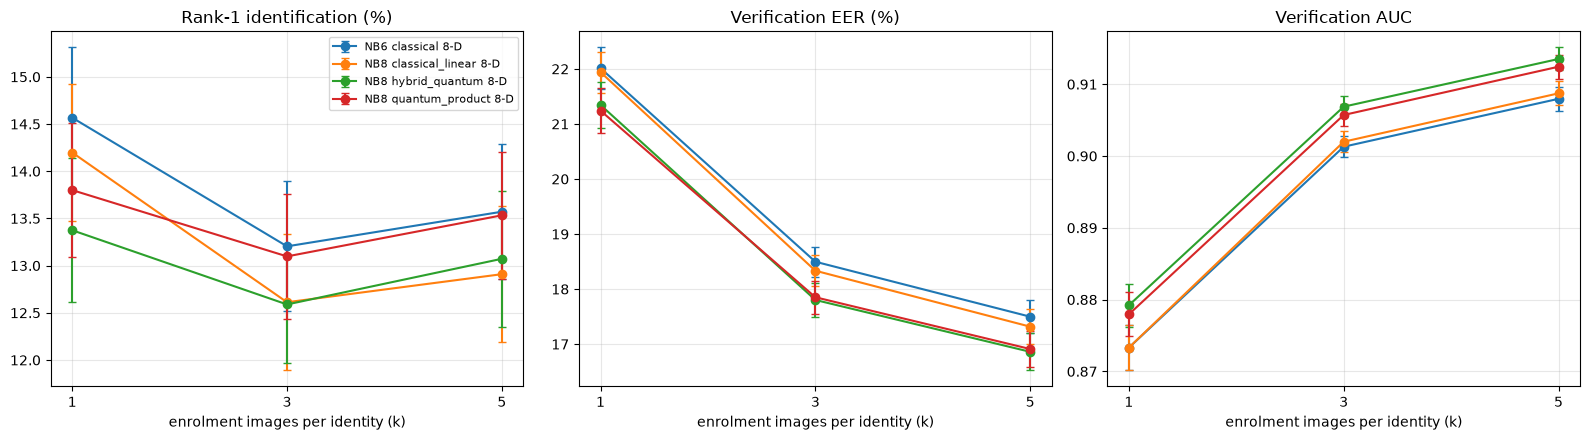

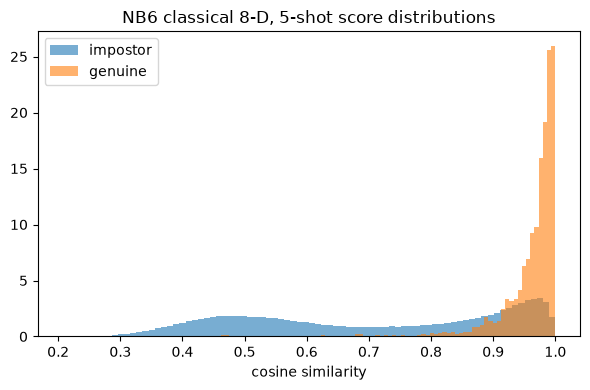

In [8]:
# CELL 8: Plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for model in EMB:
    s = summary_df[summary_df.model == model].sort_values("shots")
    ax[0].errorbar(s.shots, 100 * s.rank1, yerr=100 * s.rank1_std, marker="o", capsize=3, label=model)
    ax[1].errorbar(s.shots, 100 * s.eer, yerr=100 * s.eer_std, marker="o", capsize=3, label=model)
    ax[2].errorbar(s.shots, s.auc, yerr=s.auc_std, marker="o", capsize=3, label=model)
for a, t in zip(ax, ["Rank-1 identification (%)", "Verification EER (%)", "Verification AUC"]):
    a.set_xticks(SHOTS); a.set_xlabel("enrolment images per identity (k)"); a.set_title(t); a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "few_shot_curves.png", dpi=150); plt.show()

# score distributions for the largest k, one episode, first model
name = list(EMB)[0]; k = max(SHOTS)
support, query, qlab = make_episode(np.random.default_rng(SEED), k)
protos = l2norm(np.stack([EMB[name][s].mean(axis=0) for s in support]))
sims = EMB[name][query] @ protos.T
rows_ = np.arange(len(query)); gen = sims[rows_, qlab]
mask = np.ones_like(sims, bool); mask[rows_, qlab] = False
plt.figure(figsize=(6, 4))
plt.hist(sims[mask], bins=80, alpha=.6, density=True, label="impostor")
plt.hist(gen, bins=80, alpha=.6, density=True, label="genuine")
plt.title(f"{name}, {k}-shot score distributions"); plt.xlabel("cosine similarity"); plt.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "score_distributions.png", dpi=150); plt.show()

In [9]:
# CELL 9: Save configuration and finish
with open(OUTPUT_DIR / "few_shot_config.json", "w") as f:
    json.dump({"suffix": SUFFIX, "seed": SEED, "split": SPLIT, "shots": SHOTS, "episodes": N_EPISODES,
               "models": list(EMB), "n_identities": int(len(classes))}, f, indent=2)
print("=" * 60); print("NOTEBOOK 9 COMPLETED"); print("=" * 60)
for p in sorted(OUTPUT_DIR.iterdir()): print(" -", p.name)

NOTEBOOK 9 COMPLETED
 - episode_results.csv
 - few_shot_config.json
 - few_shot_curves.png
 - few_shot_summary.csv
 - paired_episode_comparison.csv
 - score_distributions.png
